In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import numpy as np
import matplotlib.pyplot as plt

In [2]:
sim = AerSimulator()
shots = 100

In [3]:
# Circuit 1: 0 more frequent
qc1 = QuantumCircuit(1, 1)
qc1.ry(np.pi/3, 0)
qc1.measure(0, 0)

# Circuit 2: 1 more frequent
qc2 = QuantumCircuit(1, 1)
qc2.ry(2*np.pi/3, 0)
qc2.measure(0, 0)

In [4]:
# 0 more frequent (about 85% / 15%)
qc1 = QuantumCircuit(1, 1)
qc1.h(0)
qc1.t(0)
qc1.h(0)
qc1.measure(0, 0)

# 1 more frequent (about 15% / 85%): add X at the start, 4 gates total
qc2 = QuantumCircuit(1, 1)
qc2.x(0)
qc2.h(0)
qc2.t(0)
qc2.h(0)
qc2.measure(0, 0)

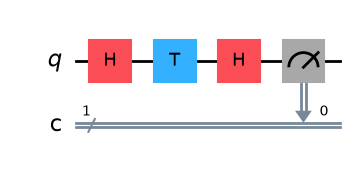

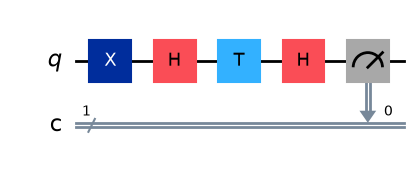

In [5]:
display(qc1.draw('mpl'))
display(qc2.draw('mpl'))

In [6]:
counts1 = sim.run(qc1, shots=shots).result().get_counts()
counts2 = sim.run(qc2, shots=shots).result().get_counts()

print("Circuit 1:", counts1)
print("Circuit 2:", counts2)

Circuit 1: {'1': 19, '0': 81}
Circuit 2: {'1': 87, '0': 13}


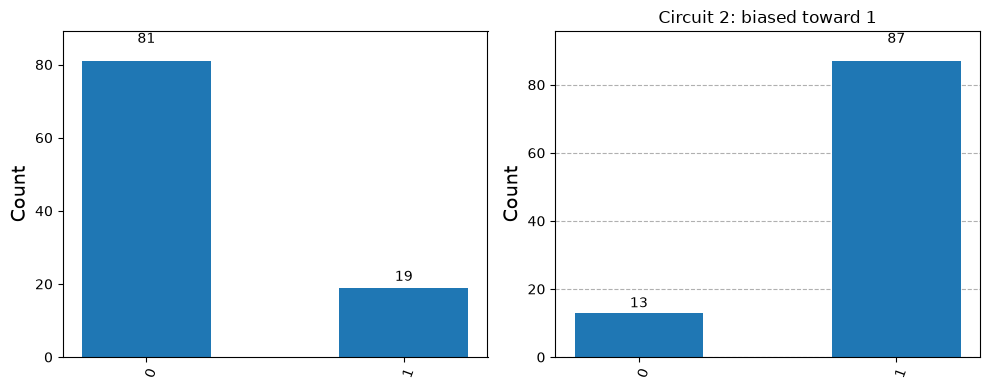

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_histogram(counts1, ax=axes[0], title="Circuit 1: biased toward 0")
plot_histogram(counts2, ax=axes[1], title="Circuit 2: biased toward 1")
plt.tight_layout()
plt.show()

In [8]:
angles = {"π/6": np.pi/6, "π/4": np.pi/4, "π/3": np.pi/3, "π/2": np.pi/2}
results = {}

for label, theta in angles.items():
    qc = QuantumCircuit(1, 1)
    qc.ry(theta, 0)
    qc.measure(0, 0)
    results[f"RY({label})"] = sim.run(qc, shots=100).result().get_counts()
    print(f"RY({label}):", results[f"RY({label})"])

plot_histogram(list(results.values()), legend=list(results.keys()))
plt.show()

RY(π/6): {'0': 91, '1': 9}
RY(π/4): {'0': 86, '1': 14}
RY(π/3): {'0': 75, '1': 25}
RY(π/2): {'0': 45, '1': 55}


In [9]:
angles = {"π/6": np.pi/6, "π/4": np.pi/4, "π/3": np.pi/3, "π/2": np.pi/2}
results = {}

for label, theta in angles.items():
    qc = QuantumCircuit(1, 1)
    qc.ry(theta, 0)
    qc.measure(0, 0)
    results[f"RY({label})"] = sim.run(qc, shots=100).result().get_counts()
    print(f"RY({label}):", results[f"RY({label})"])

plot_histogram(list(results.values()), legend=list(results.keys()))
plt.show()

RY(π/6): {'0': 98, '1': 2}
RY(π/4): {'0': 82, '1': 18}
RY(π/3): {'1': 25, '0': 75}
RY(π/2): {'1': 56, '0': 44}
